In [1]:
# Load all the libraries we need for data analysis, visualization, and machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

print("✓ Libraries imported")

<class 'ModuleNotFoundError'>: No module named 'seaborn'

In [6]:
# Read the Excel file with both objectives
file_path = 'HIT140_World_Cup_2026_FINAL.xlsx'
df_2_1 = pd.read_excel(file_path, sheet_name='Objective_2.1')
df_2_2 = pd.read_excel(file_path, sheet_name='Objective_2.2')

# Check the data loaded correctly
print(f"Objective 2.1: {df_2_1.shape}")
print(f"Objective 2.2: {df_2_2.shape}")

Objective 2.1: (104, 14)
Objective 2.2: (208, 11)


In [2]:
%pip install openpyxl -q

In [9]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load data
file_path = 'HIT140_World_Cup_2026_FINAL.xlsx'
df_2_1 = pd.read_excel(file_path, sheet_name='Objective_2.1')
df_2_2 = pd.read_excel(file_path, sheet_name='Objective_2.2')

# ===== OBJECTIVE 2.1 =====
# Use the CORRECT 8 predictors (with Head_to_Head_Record and Tournament_Stage)
X_2_1 = df_2_1[['Elo_Ranking_Difference', 'FIFA_Ranking_Difference', 
                  'Avg_Goals_Scored_Difference', 'Avg_Goals_Conceded_Difference',
                  'Head_to_Head_Record', 'Tournament_Stage',
                  'Squad_Elo_Interaction', 'Goals_Form_Interaction']]
y_2_1 = df_2_1['Goal_Difference']

# Train model
model_2_1 = LinearRegression()
model_2_1.fit(X_2_1, y_2_1)
y_pred_2_1 = model_2_1.predict(X_2_1)

# Evaluate
r2_2_1 = r2_score(y_2_1, y_pred_2_1)
rmse_2_1 = np.sqrt(mean_squared_error(y_2_1, y_pred_2_1))
mae_2_1 = mean_absolute_error(y_2_1, y_pred_2_1)

print("✓ Objective 2.1 model built")
print(f"  R² = {r2_2_1:.4f}")
print(f"  RMSE = {rmse_2_1:.4f}")
print(f"  MAE = {mae_2_1:.4f}")

✓ Objective 2.1 model built
  R² = 0.3060
  RMSE = 1.3117
  MAE = 1.0713


In [3]:
%pip install seaborn -q

In [10]:
# Calculate performance metrics
r2_2_1 = r2_score(y_2_1, y_pred_2_1)
rmse_2_1 = np.sqrt(mean_squared_error(y_2_1, y_pred_2_1))
mae_2_1 = mean_absolute_error(y_2_1, y_pred_2_1)

# Display results in a nice format
print("=" * 60)
print("OBJECTIVE 2.1: MATCH GOAL DIFFERENCE")
print("=" * 60)
print(f"R² Score:  {r2_2_1:.4f}")  # How well the model explains the variance (0-1)
print(f"RMSE:      {rmse_2_1:.4f}")  # Average prediction error
print(f"MAE:       {mae_2_1:.4f}")   # Mean absolute error
print(f"Intercept: {model_2_1.intercept_:.4f}")  # Base prediction when all features = 0
print("\nCoefficients:")

# CORRECTED: Show how much each feature impacts the prediction
coef_names_2_1 = ['Elo_Ranking_Difference', 'FIFA_Ranking_Difference', 
                   'Avg_Goals_Scored_Difference', 'Avg_Goals_Conceded_Difference',
                   'Head_to_Head_Record', 'Tournament_Stage',
                   'Squad_Elo_Interaction', 'Goals_Form_Interaction']
for name, coef in zip(coef_names_2_1, model_2_1.coef_):
    print(f"  {name}: {coef:.6f}")

OBJECTIVE 2.1: MATCH GOAL DIFFERENCE
R² Score:  0.3060
RMSE:      1.3117
MAE:       1.0713
Intercept: 0.8075

Coefficients:
  Elo_Ranking_Difference: -0.000735
  FIFA_Ranking_Difference: 0.004660
  Avg_Goals_Scored_Difference: 0.100894
  Avg_Goals_Conceded_Difference: -0.251820
  Head_to_Head_Record: 0.116788
  Tournament_Stage: -0.033814
  Squad_Elo_Interaction: -0.000001
  Goals_Form_Interaction: -0.205290


In [12]:
# Prepare data for Objective 2.2
# This predicts Goals_Scored using 8 team-level features
X_2_2 = df_2_2[['Elo_Rating', 'FIFA_Ranking', 'Avg_Goals_Scored', 
                  'Avg_Goals_Conceded', 'Squad_Value', 'Opponent_FIFA_Ranking',
                  'Opponent_Avg_Goals_Conceded', 'Team_Rest_Days']]
y_2_2 = df_2_2['Goals_Scored']

# Train the model
model_2_2 = LinearRegression()
model_2_2.fit(X_2_2, y_2_2)

# Make predictions
y_pred_2_2 = model_2_2.predict(X_2_2)

print("✓ Objective 2.2 model built")

✓ Objective 2.2 model built


In [13]:
# Calculate performance metrics for model 2.2
r2_2_2 = r2_score(y_2_2, y_pred_2_2)
rmse_2_2 = np.sqrt(mean_squared_error(y_2_2, y_pred_2_2))
mae_2_2 = mean_absolute_error(y_2_2, y_pred_2_2)

# Display results
print("=" * 60)
print("OBJECTIVE 2.2: TEAM GOALS SCORED")
print("=" * 60)
print(f"R² Score:  {r2_2_2:.4f}")
print(f"RMSE:      {rmse_2_2:.4f}")
print(f"MAE:       {mae_2_2:.4f}")
print(f"Intercept: {model_2_2.intercept_:.4f}")
print("\nCoefficients:")

coef_names_2_2 = ['Elo_Rating', 'FIFA_Ranking', 'Avg_Goals_Scored', 
                   'Avg_Goals_Conceded', 'Squad_Value', 'Opponent_FIFA_Ranking',
                   'Opponent_Avg_Goals_Conceded', 'Team_Rest_Days']
for name, coef in zip(coef_names_2_2, model_2_2.coef_):
    print(f"  {name}: {coef:.6f}")

OBJECTIVE 2.2: TEAM GOALS SCORED
R² Score:  0.3307
RMSE:      1.1401
MAE:       0.8688
Intercept: 1.3571

Coefficients:
  Elo_Rating: -0.000852
  FIFA_Ranking: -0.022441
  Avg_Goals_Scored: 0.440031
  Avg_Goals_Conceded: 0.034733
  Squad_Value: 0.000497
  Opponent_FIFA_Ranking: 0.024031
  Opponent_Avg_Goals_Conceded: 0.677020
  Team_Rest_Days: -0.030436


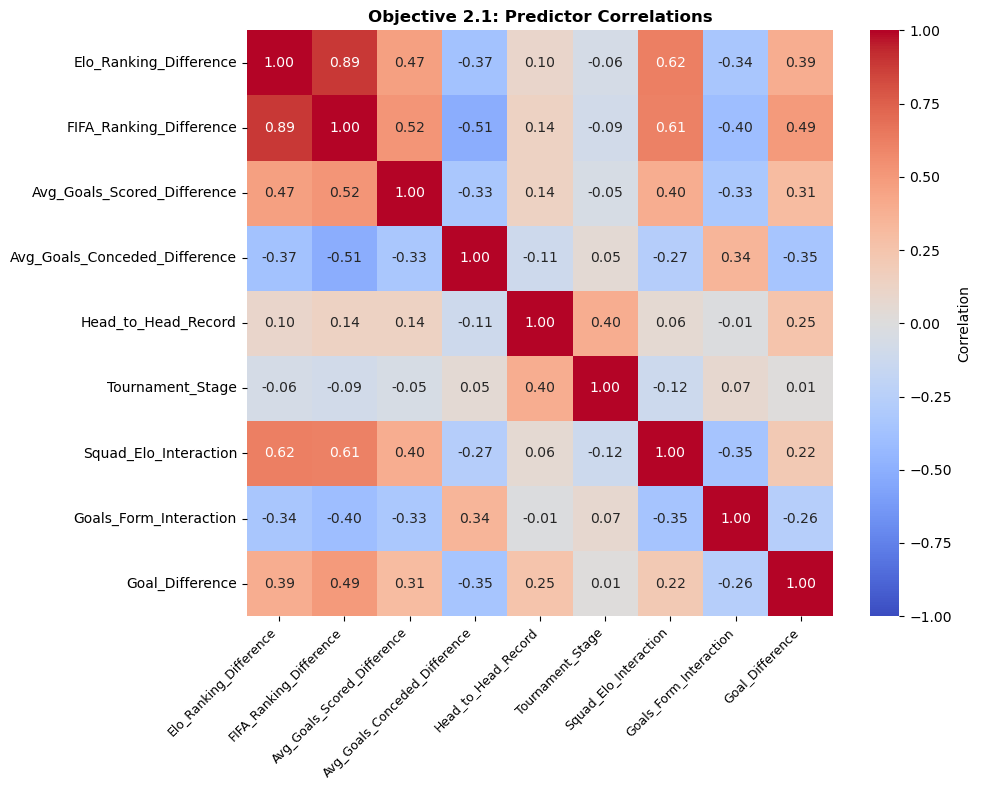

In [14]:
# Chart 1: Correlation heatmap - shows which variables are related to each other
fig, ax = plt.subplots(figsize=(10, 8))

predictors_2_1 = coef_names_2_1 + ['Goal_Difference']
corr_matrix_2_1 = df_2_1[predictors_2_1].corr()
sns.heatmap(corr_matrix_2_1, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            ax=ax, cbar_kws={'label': 'Correlation'}, vmin=-1, vmax=1)
ax.set_title('Objective 2.1: Predictor Correlations', fontsize=12, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

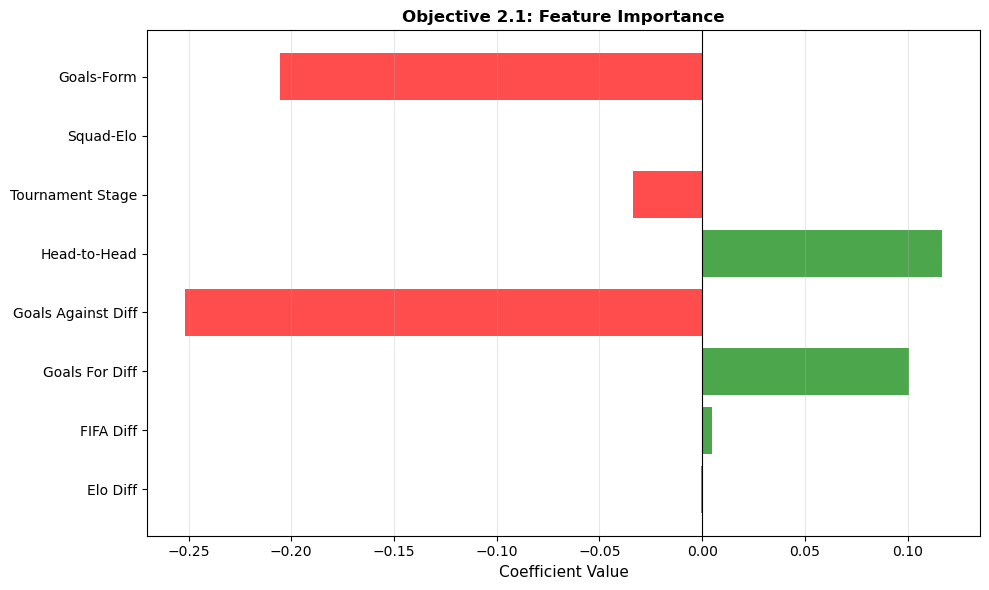

In [16]:
# Chart 2: Feature importance - which variables matter most?
fig, ax = plt.subplots(figsize=(10, 6))

# CORRECTED labels for the actual predictors
coef_names_short = ['Elo Diff', 'FIFA Diff', 'Goals For Diff', 'Goals Against Diff',
                    'Head-to-Head', 'Tournament Stage', 'Squad-Elo', 'Goals-Form']
colors = ['green' if c > 0 else 'red' for c in model_2_1.coef_]
ax.barh(coef_names_short, model_2_1.coef_, color=colors, alpha=0.7)
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.set_xlabel('Coefficient Value', fontsize=11)
ax.set_title('Objective 2.1: Feature Importance', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

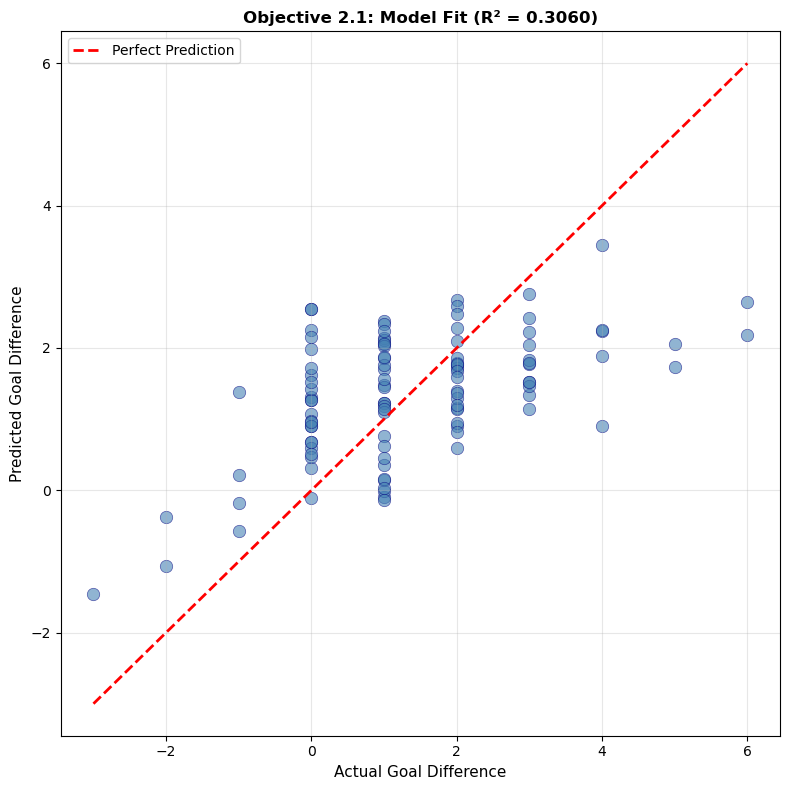

In [17]:
# Chart 3: Actual vs Predicted - how accurate is the model?
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(y_2_1, y_pred_2_1, alpha=0.6, s=80, color='steelblue', edgecolors='navy', linewidth=0.5)
min_val, max_val = min(y_2_1.min(), y_pred_2_1.min()), max(y_2_1.max(), y_pred_2_1.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
ax.set_xlabel('Actual Goal Difference', fontsize=11)
ax.set_ylabel('Predicted Goal Difference', fontsize=11)
ax.set_title(f'Objective 2.1: Model Fit (R² = {r2_2_1:.4f})', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

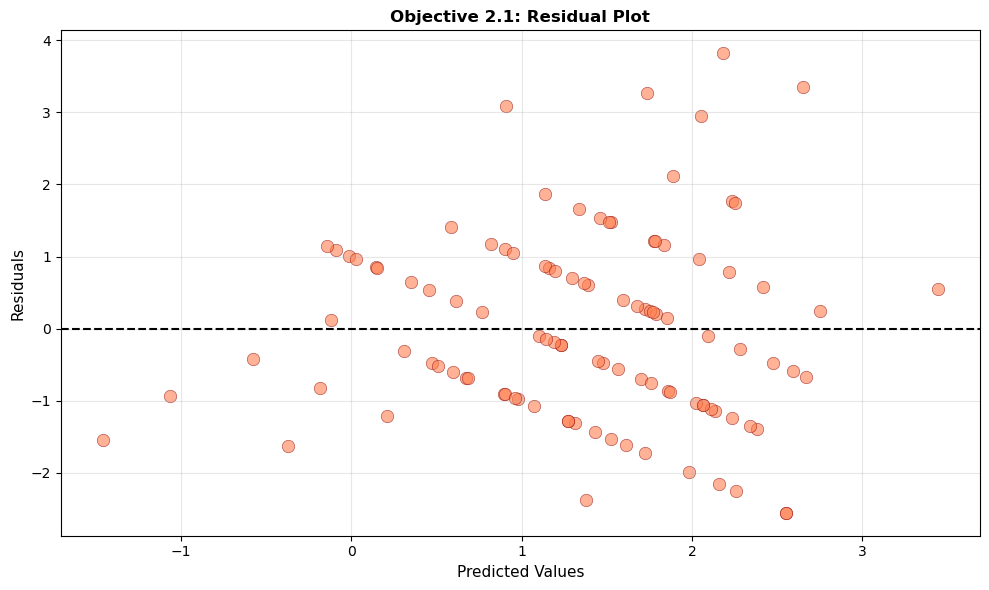

In [18]:
# Chart 4: Residuals - prediction errors
fig, ax = plt.subplots(figsize=(10, 6))

residuals_2_1 = y_2_1 - y_pred_2_1
ax.scatter(y_pred_2_1, residuals_2_1, alpha=0.6, s=80, color='coral', edgecolors='darkred', linewidth=0.5)
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Predicted Values', fontsize=11)
ax.set_ylabel('Residuals', fontsize=11)
ax.set_title('Objective 2.1: Residual Plot', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

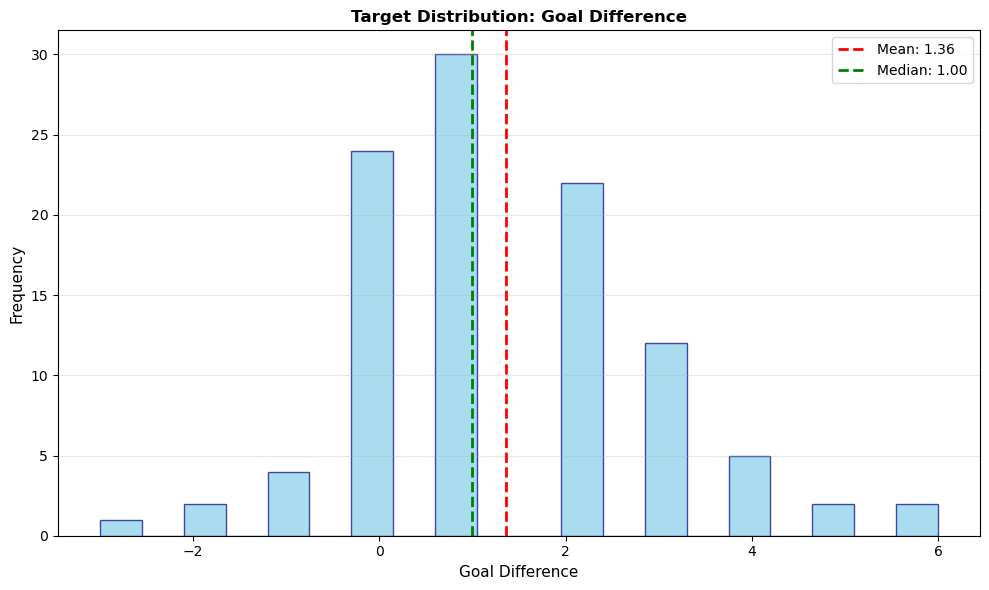

In [19]:
# Chart 5: Distribution of goal differences
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(y_2_1, bins=20, color='skyblue', edgecolor='navy', alpha=0.7)
ax.axvline(y_2_1.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {y_2_1.mean():.2f}')
ax.axvline(y_2_1.median(), color='green', linestyle='--', linewidth=2, label=f'Median: {y_2_1.median():.2f}')
ax.set_xlabel('Goal Difference', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Target Distribution: Goal Difference', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

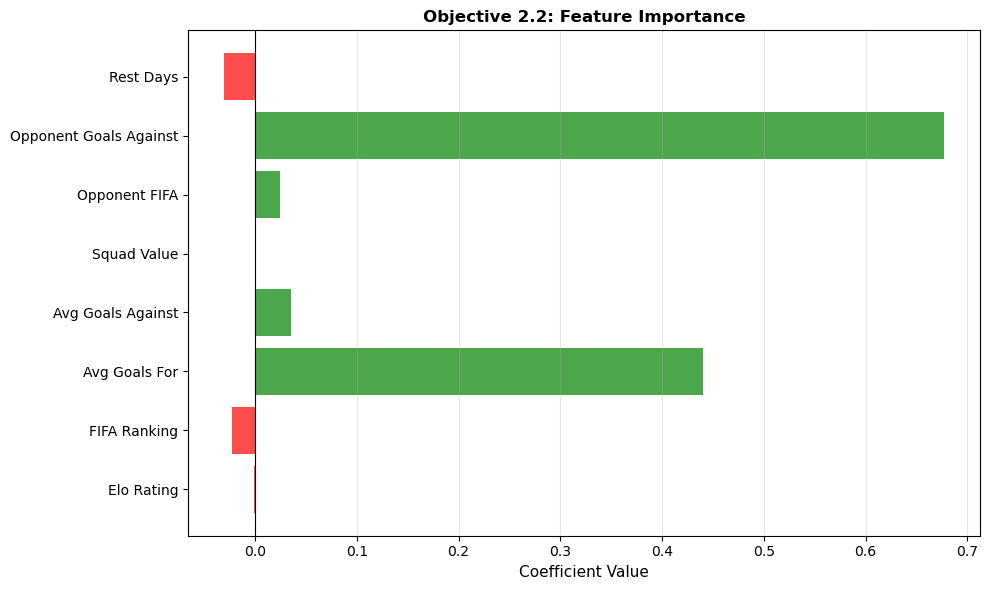

In [19]:
# Chart 6: Feature importance for Objective 2.2
fig, ax = plt.subplots(figsize=(10, 6))

coef_names_2_2_short = ['Elo Rating', 'FIFA Ranking', 'Avg Goals For', 'Avg Goals Against',
                        'Squad Value', 'Opponent FIFA', 'Opponent Goals Against', 'Rest Days']
colors_2_2 = ['green' if c > 0 else 'red' for c in model_2_2.coef_]
ax.barh(coef_names_2_2_short, model_2_2.coef_, color=colors_2_2, alpha=0.7)
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.set_xlabel('Coefficient Value', fontsize=11)
ax.set_title('Objective 2.2: Feature Importance', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

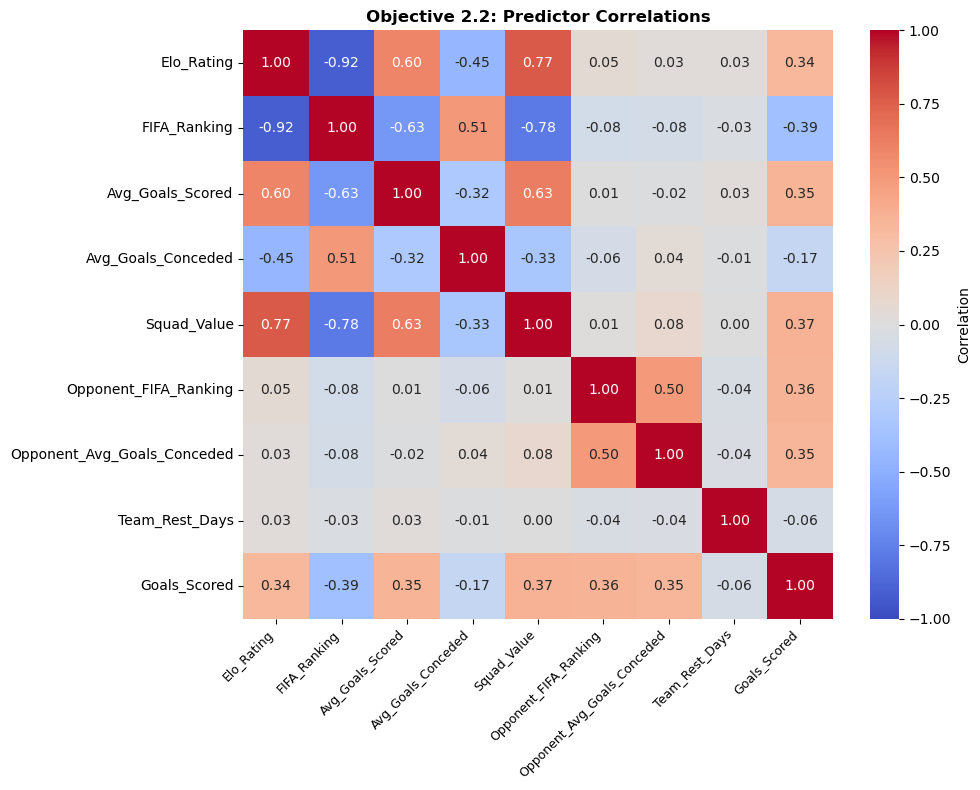

In [20]:
# Chart 7: Correlation heatmap for Objective 2.2
fig, ax = plt.subplots(figsize=(10, 8))

predictors_2_2 = coef_names_2_2 + ['Goals_Scored']
corr_matrix_2_2 = df_2_2[predictors_2_2].corr()
sns.heatmap(corr_matrix_2_2, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            ax=ax, cbar_kws={'label': 'Correlation'}, vmin=-1, vmax=1)
ax.set_title('Objective 2.2: Predictor Correlations', fontsize=12, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

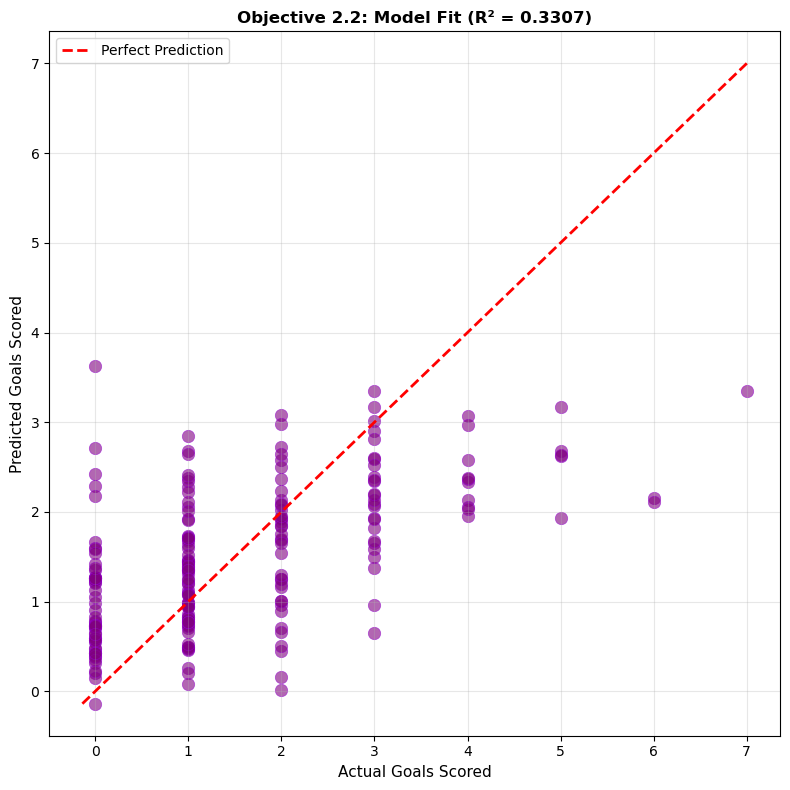

In [21]:
# Chart 8: Actual vs Predicted for Objective 2.2
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(y_2_2, y_pred_2_2, alpha=0.6, s=80, color='purple', edgecolors='darkviolet', linewidth=0.5)
min_val, max_val = min(y_2_2.min(), y_pred_2_2.min()), max(y_2_2.max(), y_pred_2_2.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
ax.set_xlabel('Actual Goals Scored', fontsize=11)
ax.set_ylabel('Predicted Goals Scored', fontsize=11)
ax.set_title(f'Objective 2.2: Model Fit (R² = {r2_2_2:.4f})', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

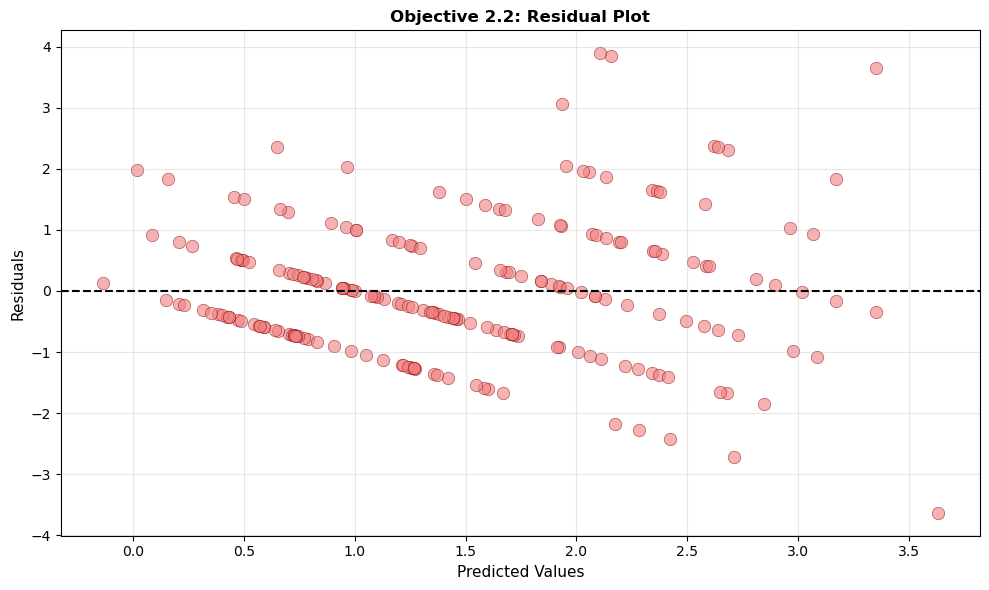

In [22]:
# Chart 9: Residuals for Objective 2.2
fig, ax = plt.subplots(figsize=(10, 6))

residuals_2_2 = y_2_2 - y_pred_2_2
ax.scatter(y_pred_2_2, residuals_2_2, alpha=0.6, s=80, color='lightcoral', edgecolors='darkred', linewidth=0.5)
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Predicted Values', fontsize=11)
ax.set_ylabel('Residuals', fontsize=11)
ax.set_title('Objective 2.2: Residual Plot', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

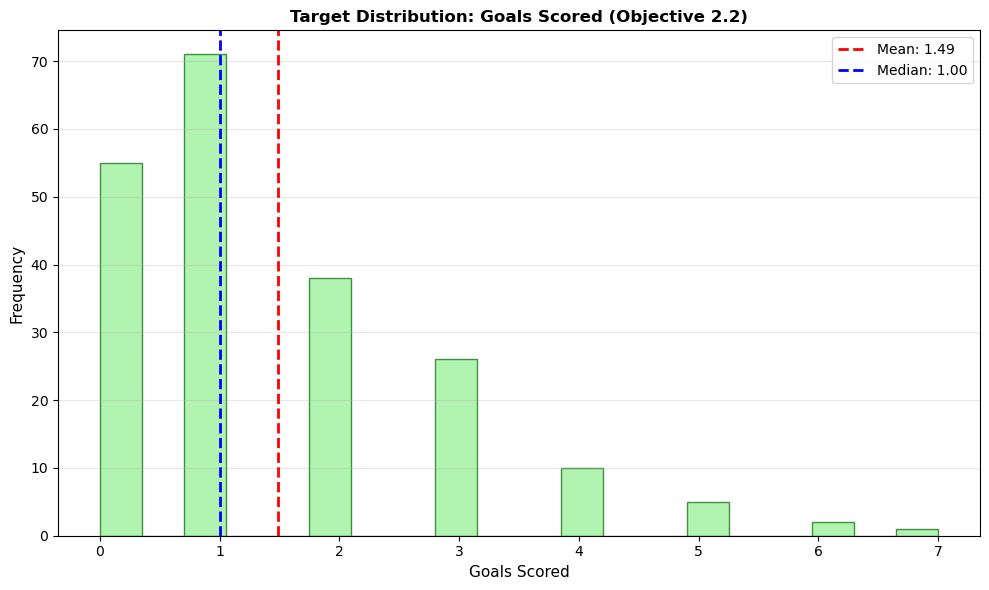

In [23]:
# Chart 10: Distribution of goals scored
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(y_2_2, bins=20, color='lightgreen', edgecolor='darkgreen', alpha=0.7)
ax.axvline(y_2_2.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {y_2_2.mean():.2f}')
ax.axvline(y_2_2.median(), color='blue', linestyle='--', linewidth=2, label=f'Median: {y_2_2.median():.2f}')
ax.set_xlabel('Goals Scored', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Target Distribution: Goals Scored (Objective 2.2)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()